# Preranked GSEA

## Setup

Download a **MEME motif database file** containing human transcription factor binding motifs from the Cis-BP resource, alongside the **human genome** in fasta format.

In [1]:
%%bash
[ -f data/cisBP_human.meme ] || wget -O data/cisBP_human.meme https://osf.io/download/uk6vn
[ -f data/GRCh38.fa ] || wget -O data/GRCh38.fa.gz https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/GRCh38.p13.genome.fa.gz
[ -f data/GRCh38.fa ] || gunzip -c data/GRCh38.fa.gz > data/GRCh38.fa

In [2]:
import gatac as ga
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sc.set_figure_params(dpi=100, frameon=False)

MOTIF_FILE = "data/cisBP_human.meme"
peak_adata = ad.read_h5ad("data/pbmc_peaks.h5ad")
# Get marker peaks for cluster 0
markers = ga.peak.markers(peak_adata, "leiden")
print("Available clusters:", list(markers.keys()))

14:09:59 - gatac.peak.markers - INFO - Running marker peak detection for groups in 'leiden'


14:10:00 - gatac.peak.markers - INFO - Testing 12 groups, 194,467 features, 5,001 cells


14:10:00 - gatac.peak.markers - INFO - Using max_cells=500 per group for balanced comparison


14:10:02 - gatac.peak.markers - INFO - Marker peak detection complete. Results stored in adata.uns['marker_peaks']


Available clusters: ['0', '1', '10', '11', '2', '3', '4', '5', '6', '7', '8', '9']


## 1. Prepare ranked peak list

In [3]:
# Use cluster 0 markers ranked by log2 fold-change
cluster = "0"
marker_df = markers[cluster].sort_values("log2_fc", ascending=False)

# Build a DataFrame indexed by peak name with the expected column name
rankings = marker_df.set_index("feature")[["log2_fc"]].rename(columns={"log2_fc": "log2fc"})
print(f"Ranked {len(rankings):,} peaks for cluster {cluster}")


Ranked 33,712 peaks for cluster 0


## 2. Build motif gene sets

Map each motif to the set of peaks that contain that motif.

In [4]:
motifs = ga.motif.read(MOTIF_FILE, unique=True)
ga.motif.scan(
    peak_adata,
    motifs=motifs,
    genome_fasta="data/GRCh38.fa",
)
motif_names = [m.name for m in motifs]
# Build gene sets: motif → list of peaks containing that motif
motif_matrix = peak_adata.varm["motif_match"]
import scipy.sparse as sp
peak_names = peak_adata.var_names.tolist()
motif_terms = {
    motif_names[j]: [peak_names[i] for i in motif_matrix[:, j].nonzero()[0]]
    for j in range(motif_matrix.shape[1])
    if motif_matrix[:, j].nnz > 0
}
print(f"Built {len(motif_terms)} motif gene sets")

14:10:02 - gatac.motif.chromvar - INFO - Scanning 1165 motifs in 194467 peaks...


14:10:02 - gatac.motif.chromvar - INFO - Using 0-based coordinate system


14:10:02 - gatac.motif.chromvar - INFO - Fetching sequences from genome...


Fetching sequences:   0%|          | 0/194467 [00:00<?, ?it/s]

14:10:04 - gatac.motif.chromvar - INFO - Background from sequences: A=0.2609 C=0.2391 G=0.2392 T=0.2608


...

Computing thresholds:   0%|          | 0/1165 [00:00<?, ?it/s]

14:10:06 - gatac.motif.chromvar - INFO - Scanning motifs on GPU in 4 batch(es) of 50000 peaks...


Peak batches:   0%|          | 0/4 [00:00<?, ?it/s]

14:14:45 - gatac.motif.chromvar - INFO - Found 17898592 motif matches (7.90% density). Stored in adata.varm['motif_match']


Built 1165 motif gene sets


In [5]:
motif_matrix = peak_adata.varm["motif_match"]
import scipy.sparse as sp
peak_names = peak_adata.var_names.tolist()
motif_terms = {
    motif_names[j]: [peak_names[i] for i in motif_matrix[:, j].nonzero()[0]]
    for j in range(motif_matrix.shape[1])
    if motif_matrix[:, j].nnz > 0
}
print(f"Built {len(motif_terms)} motif gene sets")

Built 1165 motif gene sets


## 3. Run preranked GSEA

In [6]:
import time

t0 = time.perf_counter()
gsea_df = ga.motif.gsea(
    peak_adata,
    rankings=rankings,
)
print(f"GSEA in {time.perf_counter() - t0:.1f}s")
gsea_df.nsmallest(10, "fdr")

14:16:06 - gatac.motif.motif - INFO - Built 1,165 motif feature sets (≥15 peaks; filter to ≥15)


14:16:06 - gatac.motif.motif - INFO - Running GSEA (gpu) on provided rankings...


14:16:07 - gatac.motif._gsea - INFO - GPU GSEA: 669 feature sets, 33712 features, 1000 permutations  (gs_batch=128, perm_batch=512)


GSEA scoring blocks:   0%|          | 0/14 [00:00<?, ?it/s]

GSEA in 12.4s


,motif,NES,pval,fdr,lead_edge_n,set_size,lead_edge_frac
667,TCF7L2,-1.868642,0.0,0.000996,624,1756,0.355353
666,TBX2,-1.758074,0.0,0.001327,543,1533,0.354207
668,LEF1,-1.890181,0.0,0.001991,614,1530,0.401307
659,TBX6,-1.655575,0.0,0.002489,704,1911,0.368394
654,IRX3,-1.630469,0.0,0.002522,222,451,0.492239
655,GATA2,-1.634897,0.0,0.002560,416,1141,0.364592
664,RORA,-1.699667,0.0,0.002588,368,994,0.370221
653,TBX19,-1.626754,0.0,0.002675,244,583,0.418525
656,TBR1,-1.637208,0.0,0.002680,522,1454,0.359010
665,EOMES,-1.726613,0.0,0.002738,522,1414,0.369165


## 4. GSEA enrichment plot

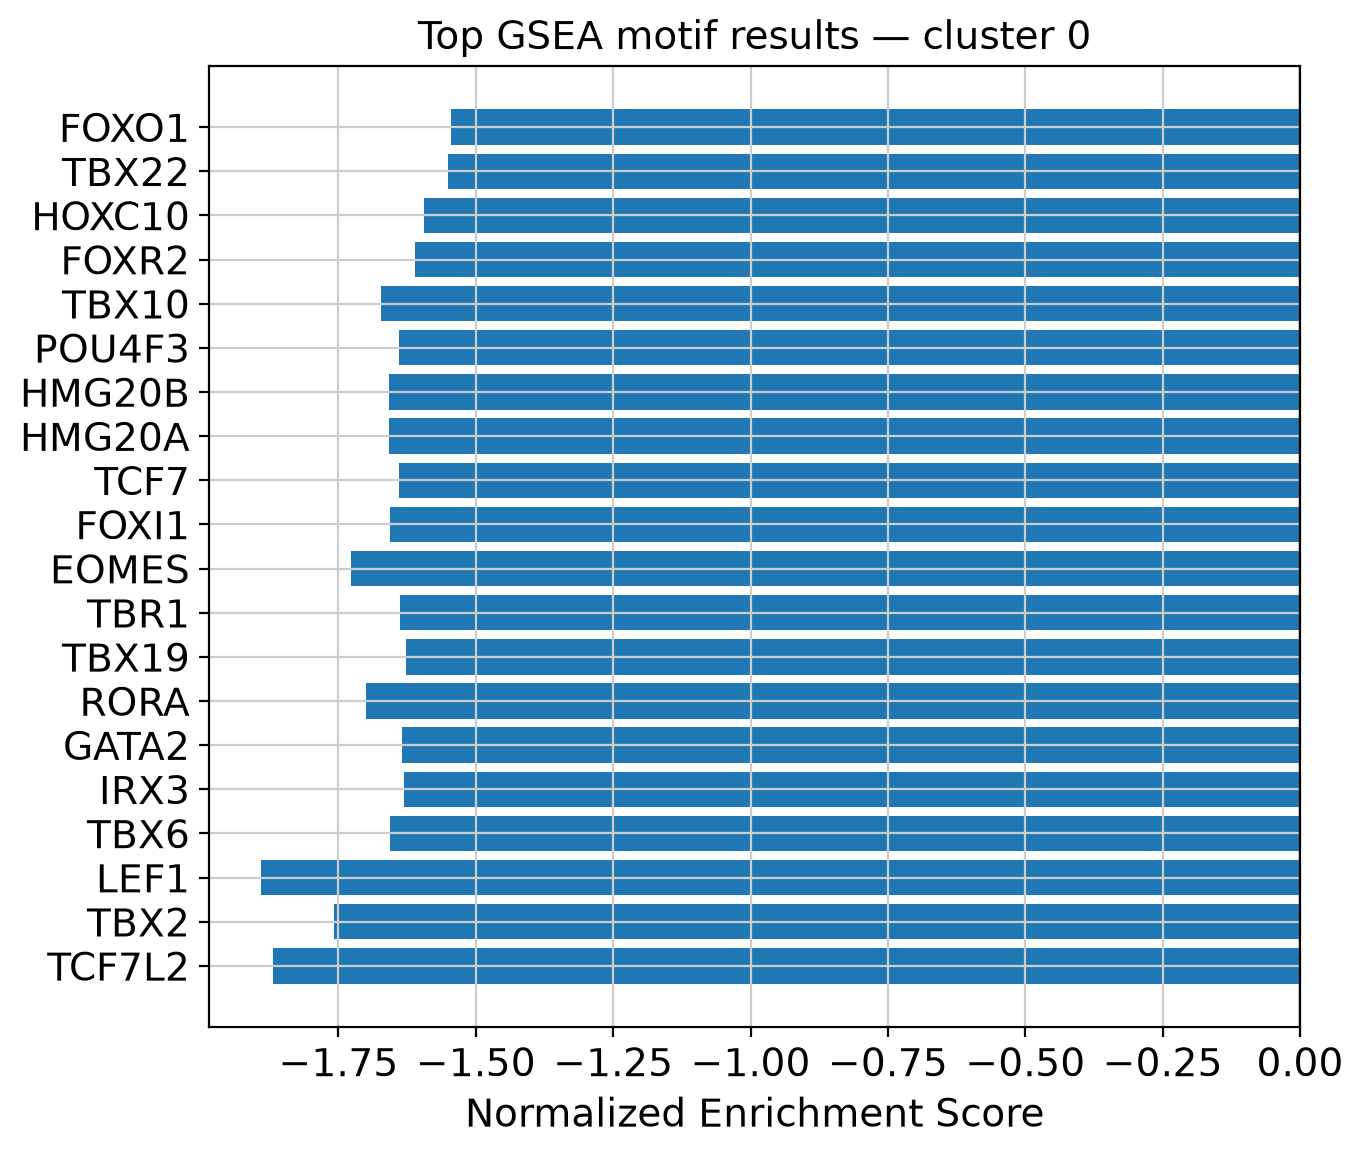

In [7]:
top_results = gsea_df.nsmallest(20, "fdr")

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#d62728" if nes > 0 else "#1f77b4" for nes in top_results["NES"]]
bars = ax.barh(range(len(top_results)), top_results["NES"], color=colors)
ax.set_yticks(range(len(top_results)))
ax.set_yticklabels(top_results["motif"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Normalized Enrichment Score")
ax.set_title(f"Top GSEA motif results — cluster {cluster}")
plt.tight_layout()
plt.show()

## Next steps

- [API: `ga.motif.gsea`](../docs/api/motif.md)